# 09 — Business Insights

## Objective
Translate findings from the movie analytics marts into actionable,
evidence-based business insights.

## Analytical areas
1. Movie portfolio composition and release trends
2. Revenue, budget, profit, and return on investment
3. Genre and language performance
4. Movie popularity and financial performance
5. Artist participation and production patterns
6. Business recommendations and executive reporting

## Analytical principles
- Validate the grain of each dataset before calculating metrics.
- Avoid double-counting movies when analysing artist or production mappings.
- Distinguish descriptive findings from causal explanations.
- Document data limitations and assumptions.
- Base recommendations on calculated evidence.

## Expected outputs
- Business KPI summary
- Performance rankings and segment comparisons
- Supporting charts
- Evidence-based findings
- Prioritized recommendations
- Executive summary

In [1]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sqlalchemy import create_engine, inspect, text
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# creating a connection to the SQLite database using SQLAlchemy
db_path = Path(r"C:\\Users\\user\\Documents\\Movie DB SQL Analytics\\Database\\TMDB-a-4006.db")

if not db_path.is_file():
    raise FileNotFoundError(f"Database file not found: {db_path}")

engine = create_engine(f"sqlite:///{db_path.as_posix()}")

print("SQLAlchemy Engine Created Successfully")

SQLAlchemy Engine Created Successfully


In [3]:
# Testing the database connection
with engine.connect() as connection:
    result = pd.read_sql(
        text("SELECT 1 AS Connection_Test"),
        connection
    )

print(result)
print("Database connection test successful!")


   Connection_Test
0                1
Database connection test successful!


In [4]:
# Inspecting the database schema
inspector = inspect(engine)

tables = inspector.get_table_names()

print("Available database tables:")
for table_name in tables:
    print(f"- {table_name}")

print("\nTable schemas:")

for table_name in tables:
    columns = inspector.get_columns(table_name)

    print(f"\n{table_name}")
    display(
        pd.DataFrame([
            {
                "column_name": col["name"],
                "data_type": str(col["type"]),
                "nullable": col.get("nullable")
            }
            for col in columns
        ])
    )

Available database tables:
- actors
- casts
- genremap
- genres
- keywordmap
- keywords
- languagemap
- languages
- movies
- oscars
- productioncompanies
- productioncompanymap
- productioncountries
- productioncountrymap
- sysdiagrams

Table schemas:

actors


,column_name,data_type,nullable
0,actor_id,INTEGER,False
1,actor_name,VARCHAR(100),True
2,gender,INTEGER,True



casts


,column_name,data_type,nullable
0,movie_id,INTEGER,False
1,actor_id,INTEGER,False
2,characters,VARCHAR(500),False



genremap


...

,column_name,data_type,nullable
0,iso_3166_1,CHAR(2),False
1,production_country_name,VARCHAR(50),True



productioncountrymap


,column_name,data_type,nullable
0,movie_id,INTEGER,True
1,iso_3166_1,CHAR(2),True



sysdiagrams


,column_name,data_type,nullable
0,name,VARCHAR(160),False
1,principal_id,INTEGER,False
2,diagram_id,INTEGER,False
3,version,INTEGER,True
4,definition,NULL,True


## 04. Load Analytical Marts

The notebook uses the movie-level mart for portfolio and financial analysis
and the artist-level mart for artist participation analysis.

Expected grains:
- Movie Master: one row per movie.
- Artist Diary: one row per artist–movie–character combination.

The grains must be validated before aggregations are performed.

In [5]:
# Loading tables into pandas DataFrames
MOVIE_MASTER_TABLE = pd.read_csv(r"C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\movie_master.csv")
ARTIST_DIARY_TABLE = pd.read_csv(r"C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\artist_diary.csv")

available_tables = set(inspector.get_table_names())

def load_table(table_name):
    """Load a database table into a pandas DataFrame."""
    if table_name not in available_tables:
        raise ValueError(
            f"Table '{table_name}' was not found. "
            f"Available tables: {sorted(available_tables)}"
        )

    with engine.connect() as connection:
        return pd.read_sql(
            text(f'SELECT * FROM "{table_name}"'),
            connection
        )


movie_master = MOVIE_MASTER_TABLE.copy()
artist_diary = ARTIST_DIARY_TABLE.copy()

print("Movie Master shape:", movie_master.shape)
print("Artist Diary shape:", artist_diary.shape)

display(movie_master.head())
display(artist_diary.head())

Movie Master shape: (4803, 11)
Artist Diary shape: (106257, 14)


,Movie_ID,Movie_Title,Release_Date,Popularity,Budget,Revenue,Genres,Keywords,Languages,Production_Companies,Production_Countries
0,5,Four Rooms,1995-12-09 00:00:00.000000,22.88,4000000,"4,300,000.00","Comedy,Crime","hotel,new year's eve,witch,bet,hotel room,sper...",English,"Miramax Films,A Band Apart",United States of America
1,11,Star Wars,1977-05-25 00:00:00.000000,126.39,11000000,"775,398,007.00","Adventure,Action,Science Fiction","android,galaxy,hermit,death star,lightsaber,je...",English,"Lucasfilm,Twentieth Century Fox Film Corporation",United States of America
2,12,Finding Nemo,2003-05-30 00:00:00.000000,85.69,94000000,"940,335,536.00","Animation,Family","father son relationship,harbor,underwater,fish...",English,Pixar Animation Studios,United States of America
3,13,Forrest Gump,1994-07-06 00:00:00.000000,138.13,55000000,"677,945,399.00","Drama,Comedy,Romance","vietnam veteran,hippie,mentally disabled,runni...",English,Paramount Pictures,United States of America
4,14,American Beauty,1999-09-15 00:00:00.000000,80.88,15000000,"356,296,601.00",Drama,"male nudity,female nudity,adultery,midlife cri...",English,"DreamWorks SKG,Jinks/Cohen Company",United States of America


,Artist_ID,Artist_Name,Gender,Character_Name,Movie_ID,Movie_Title,Release_Date,Popularity,Budget,Revenue,Genres,Languages,Production_Companies,Production_Countries
0,1496,Tod Browning,2,Crook (uncredited),3059,Intolerance,1916-09-04 00:00:00.000000,3.23,385907,"8,394,751.00",Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
1,3247,Noble Johnson,2,Babylonian Soldier (uncredited),3059,Intolerance,1916-09-04 00:00:00.000000,3.23,385907,"8,394,751.00",Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
2,8630,Erich von Stroheim,0,Second Pharisee (uncredited),3059,Intolerance,1916-09-04 00:00:00.000000,3.23,385907,"8,394,751.00",Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
3,8728,Eugene Pallette,2,Prosper Latour (French Story),3059,Intolerance,1916-09-04 00:00:00.000000,3.23,385907,"8,394,751.00",Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America
4,8820,Joseph Henabery,2,L'amiral de Coligny / Defendant,3059,Intolerance,1916-09-04 00:00:00.000000,3.23,385907,"8,394,751.00",Drama,English,"Triangle Film Corporation,Wark Producing Corp.",United States of America


In [6]:
# Checking for missing values in the DataFrames
print("MOVIE MASTER")
display(
    pd.DataFrame({
        "column": movie_master.columns,
        "dtype": movie_master.dtypes.astype(str).values,
        "missing_count": movie_master.isna().sum().values,
        "missing_pct": (
            movie_master.isna().mean().mul(100).round(2).values
        )
    })
)

print("\nARTIST DIARY")
display(
    pd.DataFrame({
        "column": artist_diary.columns,
        "dtype": artist_diary.dtypes.astype(str).values,
        "missing_count": artist_diary.isna().sum().values,
        "missing_pct": (
            artist_diary.isna().mean().mul(100).round(2).values
        )
    })
)

MOVIE MASTER


,column,dtype,missing_count,missing_pct
0,Movie_ID,int64,0,0.00
1,Movie_Title,str,0,0.00
2,Release_Date,str,1,0.02
3,Popularity,float64,0,0.00
4,Budget,int64,0,0.00
5,Revenue,float64,0,0.00
6,Genres,str,28,0.58
7,Keywords,str,412,8.58
8,Languages,str,87,1.81
9,Production_Companies,str,351,7.31



ARTIST DIARY


,column,dtype,missing_count,missing_pct
0,Artist_ID,int64,0,0.00
1,Artist_Name,str,0,0.00
2,Gender,int64,0,0.00
3,Character_Name,str,683,0.64
4,Movie_ID,int64,0,0.00
5,Movie_Title,str,0,0.00
6,Release_Date,str,0,0.00
7,Popularity,float64,0,0.00
8,Budget,int64,0,0.00
9,Revenue,float64,0,0.00


In [7]:
# Checking for duplicate rows in the DataFrames
print("Movie Master duplicate rows:", movie_master.duplicated().sum())

# Review candidate ID columns before setting the correct one.
print(
    "Potential movie ID columns:",
    [c for c in movie_master.columns if "movie" in c.lower() and "id" in c.lower()]
)

Movie Master duplicate rows: 0
Potential movie ID columns: ['Movie_ID']


In [8]:
# Checking for missing values in the DataFrames
print("Movie Master missing values:")
display(
    pd.DataFrame({
        "column": movie_master.columns,
        "missing_count": movie_master.isna().sum().values,
        "missing_pct": (
            movie_master.isna().mean().mul(100).round(2).values
        )
    })
)

MOVIE_ID_COL = "Movie_ID"

if MOVIE_ID_COL not in movie_master.columns:
    raise KeyError(
        f"{MOVIE_ID_COL} is not in Movie Master. "
        f"Available columns: {movie_master.columns.tolist()}"
    )

print("Missing movie IDs:", movie_master[MOVIE_ID_COL].isna().sum())
print("Duplicate movie IDs:", movie_master[MOVIE_ID_COL].duplicated().sum())

if movie_master[MOVIE_ID_COL].duplicated().any():
    print("WARNING: Movie Master is not at one-row-per-movie grain.")
else:
    print("PASS: Movie IDs are unique.")

Movie Master missing values:


,column,missing_count,missing_pct
0,Movie_ID,0,0.00
1,Movie_Title,0,0.00
2,Release_Date,1,0.02
3,Popularity,0,0.00
4,Budget,0,0.00
5,Revenue,0,0.00
6,Genres,28,0.58
7,Keywords,412,8.58
8,Languages,87,1.81
9,Production_Companies,351,7.31


Missing movie IDs: 0
Duplicate movie IDs: 0
PASS: Movie IDs are unique.


In [9]:
# Checking for missing values in the DataFrames
numeric_columns = movie_master.select_dtypes(include="number").columns.tolist()

print("Numeric columns available:")
for column in numeric_columns:
    print("-", column)

Numeric columns available:
- Movie_ID
- Popularity
- Budget
- Revenue


In [10]:
# Column Mapping
COLUMN_MAP = {
    "movie_id": "Movie_ID",
    "title": "Movie_Title",
    "budget": "Budget",
    "revenue": "Revenue",
    "popularity": "Popularity",
    "release_date": "Release_Date",
    "genres": "Genres",
    "languages": "Languages",
    "production_companies": "Production_Companies",
    "production_countries": "Production_Countries"
}

# Check which configured fields actually exist.
for role, column in COLUMN_MAP.items():
    status = "FOUND" if column in movie_master.columns else "NOT FOUND"
    print(f"{role:25} | {column:25} | {status}")

movie_id                  | Movie_ID                  | FOUND
title                     | Movie_Title               | FOUND
budget                    | Budget                    | FOUND
revenue                   | Revenue                   | FOUND
popularity                | Popularity                | FOUND
release_date              | Release_Date              | FOUND
genres                    | Genres                    | FOUND
languages                 | Languages                 | FOUND
production_companies      | Production_Companies      | FOUND
production_countries      | Production_Countries      | FOUND


In [11]:
# Calculate financial metrics using an explicitly validated movie-level population.
required_financial_columns = [
    COLUMN_MAP["movie_id"],
    COLUMN_MAP["budget"],
    COLUMN_MAP["revenue"],
]
missing_columns = [
    column for column in required_financial_columns
    if column not in movie_master.columns
]
if missing_columns:
    raise KeyError(f"Missing required financial columns: {missing_columns}")

if movie_master[COLUMN_MAP["movie_id"]].duplicated().any():
    raise ValueError("Resolve duplicate Movie_ID values before financial analysis.")

financial_df = movie_master.copy()
budget_col = COLUMN_MAP["budget"]
revenue_col = COLUMN_MAP["revenue"]

financial_df[budget_col] = pd.to_numeric(financial_df[budget_col], errors="coerce")
financial_df[revenue_col] = pd.to_numeric(financial_df[revenue_col], errors="coerce")

budget_values = financial_df[budget_col]
revenue_values = financial_df[revenue_col]

finite_budget = budget_values.notna() & np.isfinite(budget_values)
finite_revenue = revenue_values.notna() & np.isfinite(revenue_values)

# A valid financial record requires a strictly positive budget and
# a recorded, non-negative revenue. Missing revenue is never replaced by zero.
valid_budget = finite_budget & (budget_values > 0)
valid_revenue = finite_revenue & (revenue_values >= 0)
valid_financial = valid_budget & valid_revenue

financial_df["Profit"] = np.nan
financial_df.loc[valid_financial, "Profit"] = (
    financial_df.loc[valid_financial, revenue_col]
    - financial_df.loc[valid_financial, budget_col]
)

financial_df["ROI"] = np.nan
financial_df.loc[valid_financial, "ROI"] = (
    financial_df.loc[valid_financial, "Profit"]
    / financial_df.loc[valid_financial, budget_col]
)

conditions = [
    ~finite_budget | ~finite_revenue,
    finite_budget & (budget_values <= 0),
    finite_revenue & (revenue_values < 0),
    valid_financial & (financial_df["Profit"] > 0),
    valid_financial & (financial_df["Profit"] == 0),
    valid_financial & (financial_df["Profit"] < 0),
]
choices = [
    "Incomplete Financial Data",
    "Invalid or Zero Budget",
    "Invalid Revenue",
    "Profitable",
    "Break-even",
    "Loss-making",
]
financial_df["Financial_Status"] = np.select(
    conditions, choices, default="Unclassified"
)

print(f"Total movies: {len(financial_df):,}")
print(f"Valid financial records: {int(valid_financial.sum()):,}")
print(f"Excluded from financial analysis: {int((~valid_financial).sum()):,}")
display(
    financial_df[
        [
            COLUMN_MAP["movie_id"], budget_col, revenue_col,
            "Profit", "ROI", "Financial_Status"
        ]
    ].head(10)
)


Total movies: 4,803
Valid financial records: 3,766
Excluded from financial analysis: 1,037


,Movie_ID,Budget,Revenue,Profit,ROI,Financial_Status
0,5,4000000,"4,300,000.00","300,000.00",0.07,Profitable
1,11,11000000,"775,398,007.00","764,398,007.00",69.49,Profitable
2,12,94000000,"940,335,536.00","846,335,536.00",9.00,Profitable
3,13,55000000,"677,945,399.00","622,945,399.00",11.33,Profitable
4,14,15000000,"356,296,601.00","341,296,601.00",22.75,Profitable
5,16,12800000,"40,031,879.00","27,231,879.00",2.13,Profitable
6,18,90000000,"263,920,180.00","173,920,180.00",1.93,Profitable
7,19,92620000,"650,422.00","-91,969,578.00",-0.99,Loss-making
8,20,0,"9,726,954.00",NaN,NaN,Invalid or Zero Budget
9,22,140000000,"655,011,224.00","515,011,224.00",3.68,Profitable


In [12]:
# Calculate financial KPIs with consistent denominators and populations.
financial_kpis = pd.DataFrame({
    "Metric": [
        "Total movies",
        "Movies with recorded non-negative revenue",
        "Movies with valid positive budget and recorded non-negative revenue",
        "Movies excluded from financial analysis",
        "Total budget among valid financial records",
        "Total revenue among valid financial records",
        "Total simplified profit among valid financial records",
        "Median revenue among records with valid revenue",
        "Median ROI among valid financial records",
        "Profitable movies among valid financial records",
        "Loss-making movies among valid financial records",
        "Break-even movies among valid financial records",
    ],
    "Value": [
        len(financial_df),
        int(valid_revenue.sum()),
        int(valid_financial.sum()),
        int((~valid_financial).sum()),
        financial_df.loc[valid_financial, budget_col].sum(min_count=1),
        financial_df.loc[valid_financial, revenue_col].sum(min_count=1),
        financial_df.loc[valid_financial, "Profit"].sum(min_count=1),
        financial_df.loc[valid_revenue, revenue_col].median(),
        financial_df.loc[valid_financial, "ROI"].median(),
        int((financial_df.loc[valid_financial, "Profit"] > 0).sum()),
        int((financial_df.loc[valid_financial, "Profit"] < 0).sum()),
        int((financial_df.loc[valid_financial, "Profit"] == 0).sum()),
    ]
})
display(financial_kpis)


,Metric,Value
0,Total movies,"4,803.00"
1,Movies with recorded non-negative revenue,"4,803.00"
2,Movies with valid positive budget and recorded...,"3,766.00"
3,Movies excluded from financial analysis,"1,037.00"
4,Total budget among valid financial records,"139,503,326,521.00"
5,Total revenue among valid financial records,"391,493,508,997.00"
6,Total simplified profit among valid financial ...,"251,990,182,476.00"
7,Median revenue among records with valid revenue,"19,170,001.00"
8,Median ROI among valid financial records,0.87
9,Profitable movies among valid financial records,"2,438.00"


In [13]:
# Displaying top 10 movies by revenue
title_col = COLUMN_MAP["title"]

if title_col not in financial_df.columns:
    financial_df["Movie_Title_Display"] = (
        financial_df[COLUMN_MAP["movie_id"]].astype(str)
    )
    title_col = "Movie_Title_Display"

top_revenue_movies = (
    financial_df.loc[valid_revenue]
    .sort_values(revenue_col, ascending=False)
    [[COLUMN_MAP["movie_id"], title_col, budget_col, revenue_col, "Profit", "ROI"]]
    .head(10)
)

display(top_revenue_movies)

,Movie_ID,Movie_Title,Budget,Revenue,Profit,ROI
2702,19995,Avatar,237000000,"2,787,965,087.00","2,550,965,087.00",10.76
256,597,Titanic,200000000,"1,845,034,188.00","1,645,034,188.00",8.23
2861,24428,The Avengers,220000000,"1,519,557,910.00","1,299,557,910.00",5.91
4108,135397,Jurassic World,150000000,"1,513,528,810.00","1,363,528,810.00",9.09
4204,168259,Furious 7,190000000,"1,506,249,360.00","1,316,249,360.00",6.93
3983,99861,Avengers: Age of Ultron,280000000,"1,405,403,694.00","1,125,403,694.00",4.02
4025,109445,Frozen,150000000,"1,274,219,009.00","1,124,219,009.00",7.49
3704,68721,Iron Man 3,200000000,"1,215,439,994.00","1,015,439,994.00",5.08
4327,211672,Minions,74000000,"1,156,730,962.00","1,082,730,962.00",14.63
4519,271110,Captain America: Civil War,250000000,"1,153,304,495.00","903,304,495.00",3.61


In [14]:
# Displaying top 10 movies by ROI
MIN_BUDGET = 1  # Replace with a meaningful threshold for your dataset.

top_roi_movies = (
    financial_df.loc[
        valid_financial
        & (financial_df[budget_col] >= MIN_BUDGET)
    ]
    .sort_values("ROI", ascending=False)
    [[COLUMN_MAP["movie_id"], title_col, budget_col, revenue_col, "Profit", "ROI"]]
    .head(10)
)

display(top_roi_movies)

,Movie_ID,Movie_Title,Budget,Revenue,Profit,ROI
791,3082,Modern Times,1,"8,500,000.00","8,499,999.00","8,499,999.00"
3839,78383,Nurse 3-D,10,"10,000,000.00","9,999,990.00","999,999.00"
2838,23827,Paranormal Activity,15000,"193,355,800.00","193,340,800.00","12,889.39"
490,1435,Tarnation,218,"1,162,014.00","1,161,796.00","5,329.34"
751,2667,The Blair Witch Project,60000,"248,000,000.00","247,940,000.00","4,132.33"
432,985,Eraserhead,10000,"7,000,000.00","6,990,000.00",699.00
312,692,Pink Flamingos,12000,"6,000,000.00","5,988,000.00",499.00
1284,9372,Super Size Me,65000,"28,575,078.00","28,510,078.00",438.62
4616,299245,The Gallows,100000,"42,664,410.00","42,564,410.00",425.64
34,83,Open Water,130000,"54,667,954.00","54,537,954.00",419.52


,Financial_Status,Movie_Count
0,Profitable,2438
1,Loss-making,1326
2,Invalid or Zero Budget,1037
3,Break-even,2


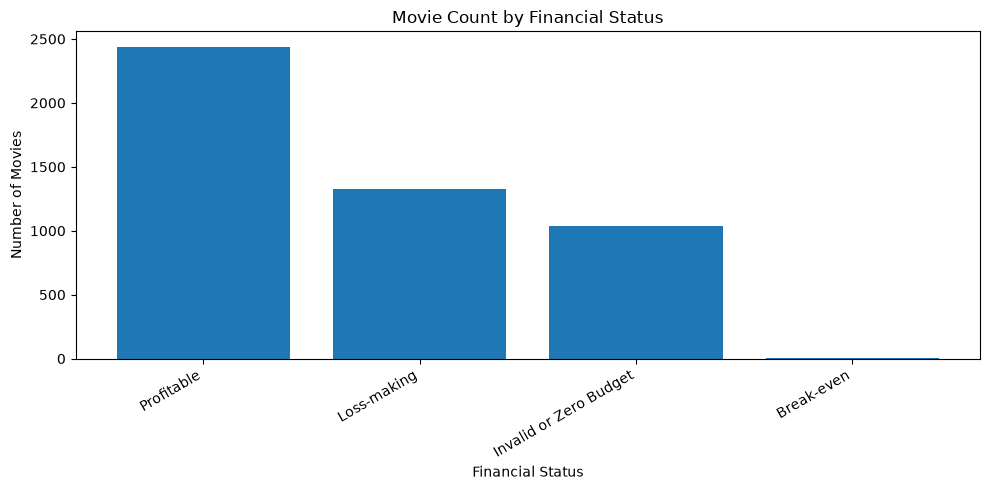

In [15]:
# Visualizing the distribution of financial status
status_counts = (
    financial_df["Financial_Status"]
    .value_counts()
    .rename_axis("Financial_Status")
    .reset_index(name="Movie_Count")
)

display(status_counts)

plt.figure(figsize=(10, 5))
plt.bar(status_counts["Financial_Status"], status_counts["Movie_Count"])
plt.title("Movie Count by Financial Status")
plt.xlabel("Financial Status")
plt.ylabel("Number of Movies")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

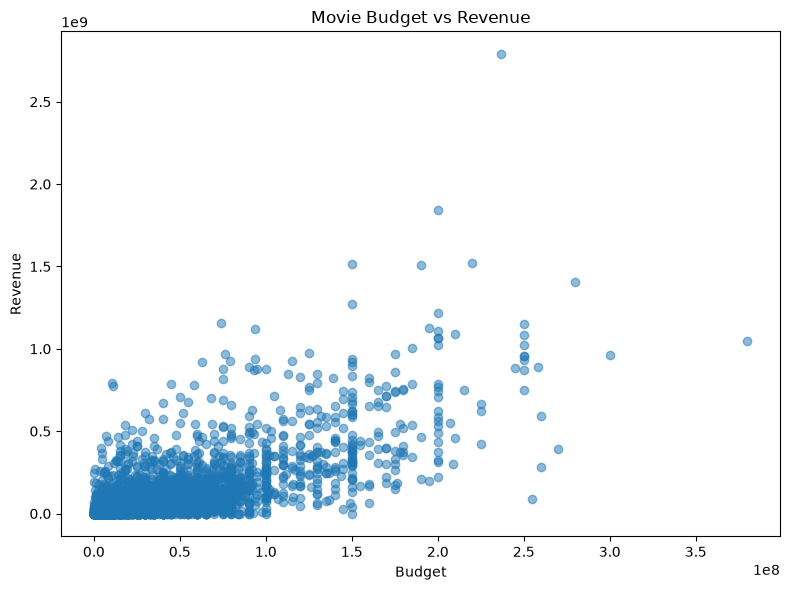

Budget–revenue Pearson correlation: 0.710


In [16]:
# Visualizing the relationship between budget and revenue
plot_df = financial_df.loc[
    valid_financial
    & (financial_df[budget_col] >= 0)
    & (financial_df[revenue_col] >= 0)
]

plt.figure(figsize=(8, 6))
plt.scatter(plot_df[budget_col], plot_df[revenue_col], alpha=0.5)
plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

if len(plot_df) >= 2:
    correlation = plot_df[budget_col].corr(plot_df[revenue_col])
    print(f"Budget–revenue Pearson correlation: {correlation:.3f}")
else:
    print("Not enough valid records to calculate correlation.")

,Release_Year,Movie_Count
70,"1,998.00",133
71,"1,999.00",171
72,"2,000.00",166
73,"2,001.00",183
74,"2,002.00",203
75,"2,003.00",169
76,"2,004.00",204
77,"2,005.00",217
78,"2,006.00",237
79,"2,007.00",195


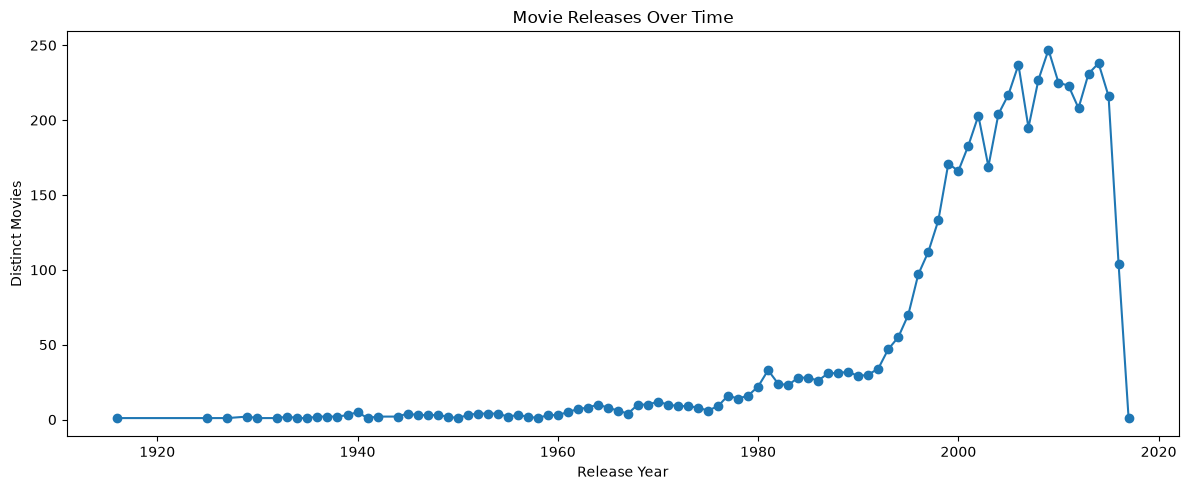

In [17]:
# Visualizing movie releases over time
release_col = COLUMN_MAP["release_date"]

if release_col in movie_master.columns:
    movie_master["Release_Date_Parsed"] = pd.to_datetime(
        movie_master[release_col], errors="coerce"
    )
    movie_master["Release_Year"] = (
        movie_master["Release_Date_Parsed"].dt.year
    )

    year_trend = (
        movie_master.dropna(subset=["Release_Year"])
        .groupby("Release_Year")
        .agg(Movie_Count=(MOVIE_ID_COL, "nunique"))
        .reset_index()
        .sort_values("Release_Year")
    )

    display(year_trend.tail(20))

    plt.figure(figsize=(12, 5))
    plt.plot(
        year_trend["Release_Year"],
        year_trend["Movie_Count"],
        marker="o"
    )
    plt.title("Movie Releases Over Time")
    plt.xlabel("Release Year")
    plt.ylabel("Distinct Movies")
    plt.tight_layout()
    plt.show()
else:
    print(
        f"Release date column '{release_col}' was not found. "
        "Update COLUMN_MAP before running release analysis."
    )

## Genre Performance

Genres are usually a many-to-many attribute: a movie may belong to
multiple genres.

Before calculating genre-level counts or revenue:
1. Split the genre list into one row per movie–genre.
2. Normalize whitespace and missing values.
3. Count distinct movies per genre.
4. Join financial metrics at movie grain.
5. Aggregate financial measures without multiplying movie values.

Important: genre-level revenue totals overlap when a movie belongs to
multiple genres. These totals describe each genre's associated movies;
they should not be summed across genres as if the categories were exclusive.

,Genre,Movie_Count
6,Drama,2297
3,Comedy,1722
17,Thriller,1274
0,Action,1154
14,Romance,894
1,Adventure,790
4,Crime,696
15,Science Fiction,535
11,Horror,519
7,Family,513


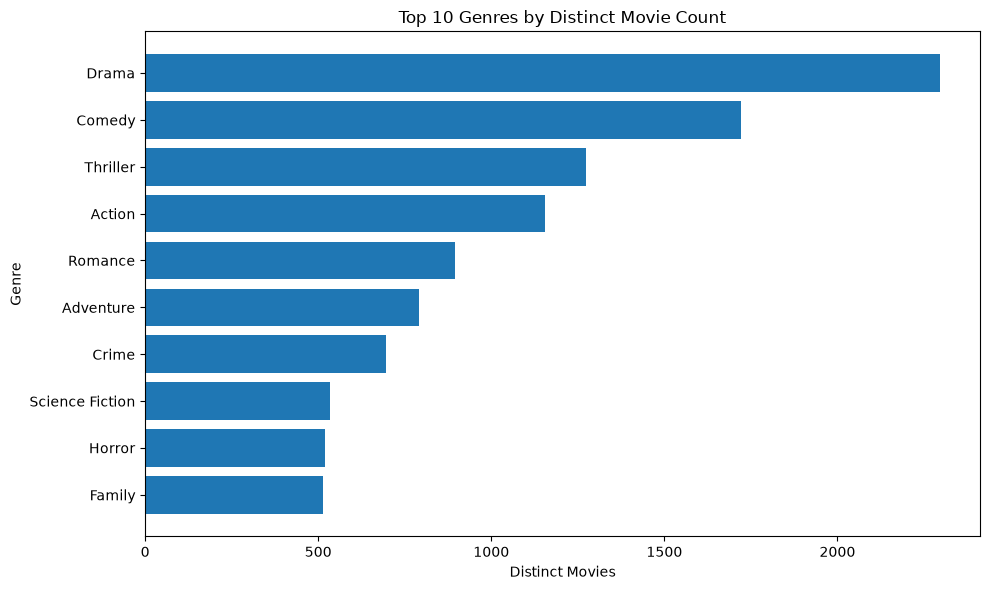

In [18]:
# Analyzing movie genres
genre_col = COLUMN_MAP["genres"]

if genre_col in movie_master.columns:
    genre_df = movie_master[
        [MOVIE_ID_COL, genre_col]
    ].copy()

    genre_df[genre_col] = genre_df[genre_col].fillna("").astype(str)

    genre_df["Genre"] = genre_df[genre_col].str.split(",")
    genre_df = genre_df.explode("Genre")

    genre_df["Genre"] = genre_df["Genre"].str.strip()
    genre_df = genre_df.loc[genre_df["Genre"].ne("")]

    genre_df = genre_df.drop_duplicates([MOVIE_ID_COL, "Genre"])

    genre_summary = (
        genre_df.groupby("Genre")
        .agg(
            Movie_Count=(MOVIE_ID_COL, "nunique")
        )
        .reset_index()
        .sort_values("Movie_Count", ascending=False)
    )

    display(genre_summary.head(15))

    plt.figure(figsize=(10, 6))
    top_genres = genre_summary.head(10).sort_values("Movie_Count")
    plt.barh(top_genres["Genre"], top_genres["Movie_Count"])
    plt.title("Top 10 Genres by Distinct Movie Count")
    plt.xlabel("Distinct Movies")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()
else:
    print(f"Genre column '{genre_col}' not found. Update COLUMN_MAP.")

Popularity–revenue Pearson correlation: 0.645


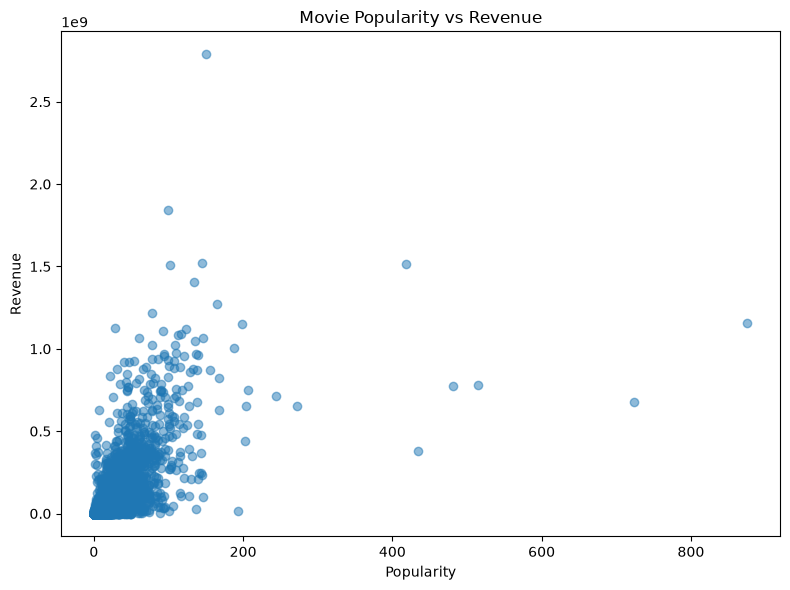

In [19]:
# Analyzing the relationship between popularity and revenue
popularity_col = COLUMN_MAP["popularity"]

if popularity_col in financial_df.columns:
    financial_df[popularity_col] = pd.to_numeric(
        financial_df[popularity_col], errors="coerce"
    )

    popularity_df = financial_df.loc[
        financial_df[popularity_col].notna()
        & financial_df[revenue_col].notna()
    ]

    if len(popularity_df) >= 2:
        corr = popularity_df[popularity_col].corr(
            popularity_df[revenue_col]
        )
        print(f"Popularity–revenue Pearson correlation: {corr:.3f}")

        plt.figure(figsize=(8, 6))
        plt.scatter(
            popularity_df[popularity_col],
            popularity_df[revenue_col],
            alpha=0.5
        )
        plt.title("Movie Popularity vs Revenue")
        plt.xlabel("Popularity")
        plt.ylabel("Revenue")
        plt.tight_layout()
        plt.show()
    else:
        print("Insufficient valid data for this comparison.")
else:
    print(f"Popularity column '{popularity_col}' not found.")

## Artist Participation

The Artist Diary contains artist–movie–character records. A movie can
therefore appear multiple times.

Use Artist Diary for:
- Artist participation counts
- Number of distinct movies per artist
- Character-level participation
- Artist collaboration analysis

Do not sum movie revenue directly from Artist Diary. First deduplicate
to one record per movie for financial analysis, or aggregate at the
artist–movie level and explicitly label the result as associated movie
revenue rather than revenue attributable to the artist.

In [20]:
# Analyzing artist contributions
artist_id_col = "Artist_ID"
artist_name_col = "Artist_Name"

required_artist_cols = [artist_id_col, artist_name_col, MOVIE_ID_COL]

missing_artist_cols = [
    col for col in required_artist_cols
    if col not in artist_diary.columns
]

if missing_artist_cols:
    print(
        "Update artist column mappings before proceeding. "
        f"Missing columns: {missing_artist_cols}"
    )
else:
    artist_movie_counts = (
        artist_diary[
            [artist_id_col, artist_name_col, MOVIE_ID_COL]
        ]
        .dropna(subset=[artist_id_col, MOVIE_ID_COL])
        .drop_duplicates([artist_id_col, MOVIE_ID_COL])
        .groupby([artist_id_col, artist_name_col])
        .agg(
            Distinct_Movies=(MOVIE_ID_COL, "nunique")
        )
        .reset_index()
        .sort_values("Distinct_Movies", ascending=False)
    )

    display(artist_movie_counts.head(20))

,Artist_ID,Artist_Name,Distinct_Movies
931,2231,Samuel L. Jackson,67
169,380,Robert De Niro,57
33,62,Bruce Willis,51
762,1892,Matt Damon,48
79,192,Morgan Freeman,46
380,884,Steve Buscemi,43
1571,3896,Liam Neeson,41
48,85,Johnny Depp,40
382,887,Owen Wilson,40
515,1230,John Goodman,39


## Business Recommendations

Each recommendation must contain:

1. **Finding:** What did the analysis show?
2. **Evidence:** Which metric, comparison, or table supports it?
3. **Business implication:** Why does it matter?
4. **Recommended action:** What should the decision-maker do?
5. **Limitation:** What can the available data not establish?
6. **Follow-up analysis:** What additional evidence is required?

## 10. Build an Evidence-Based Insight Register

This section converts existing analyses into findings using calculations from the current notebook runtime. It does not hard-code previously observed numbers. Re-run the notebook from the top so the register reflects the current CSV files.

**Financial population:** one row per movie, budget greater than zero, and recorded finite revenue greater than or equal to zero. Missing revenue is not treated as zero. Genre, production-company, and country categories can overlap because a movie may belong to more than one category; category counts and medians must not be summed across categories.


In [21]:
# Helpers for clear, reproducible evidence statements.
def _fmt_int(value):
    return f"{int(value):,}"

def _fmt_pct(value, decimals=1):
    return f"{value * 100:,.{decimals}f}%"

def _nonblank_split_counts(data, id_col, category_col):
    """Count distinct movies associated with each comma-separated category."""
    if category_col not in data.columns or id_col not in data.columns:
        return pd.DataFrame(columns=["Category", "Movie_Count"])
    work = data[[id_col, category_col]].copy()
    work[category_col] = work[category_col].fillna("").astype(str)
    work["Category"] = work[category_col].str.split(",")
    work = work.explode("Category")
    work["Category"] = work["Category"].astype(str).str.strip()
    work = work.loc[work["Category"].ne("") & work["Category"].str.lower().ne("nan")]
    work = work.drop_duplicates([id_col, "Category"])
    return (
        work.groupby("Category")[id_col].nunique()
        .rename("Movie_Count").reset_index()
        .sort_values("Movie_Count", ascending=False)
    )

# Re-check the Movie Master grain before producing business findings.
movie_id_col = COLUMN_MAP["movie_id"]
if movie_master[movie_id_col].isna().any():
    raise ValueError("Movie Master contains missing Movie_ID values.")
if movie_master[movie_id_col].duplicated().any():
    raise ValueError("Movie Master is not unique at Movie_ID grain.")

total_movies = movie_master[movie_id_col].nunique()
valid_financial_count = int(valid_financial.sum())
excluded_financial_count = int((~valid_financial).sum())

insight_rows = []

def add_insight(
    insight_id, business_area, business_question, finding, evidence,
    implication, recommendation, priority, confidence, limitation,
    follow_up
):
    insight_rows.append({
        "Insight_ID": insight_id,
        "Business_Area": business_area,
        "Business_Question": business_question,
        "Finding": finding,
        "Supporting_Evidence": evidence,
        "Business_Implication": implication,
        "Recommendation": recommendation,
        "Priority": priority,
        "Confidence_Level": confidence,
        "Data_Limitation": limitation,
        "Follow_Up_Analysis": follow_up,
    })

# BI001 — Portfolio composition by genre
genre_col = COLUMN_MAP.get("genres")
genre_summary_current = _nonblank_split_counts(movie_master, movie_id_col, genre_col)
if not genre_summary_current.empty:
    top_genre = genre_summary_current.iloc[0]
    tagged_movie_ids = movie_master.loc[
        movie_master[genre_col].notna()
        & movie_master[genre_col].astype(str).str.strip().ne(""),
        movie_id_col
    ].nunique()
    add_insight(
        "BI001", "Portfolio", "How is the movie catalogue distributed?",
        f"{top_genre['Category']} is the most represented genre in the catalogue, associated with {_fmt_int(top_genre['Movie_Count'])} distinct movies.",
        f"Movie Master contains {_fmt_int(total_movies)} distinct movies. {_fmt_int(tagged_movie_ids)} have a nonblank genre field. The leading genre is associated with {_fmt_int(top_genre['Movie_Count'])} movies ({_fmt_pct(top_genre['Movie_Count'] / total_movies)} of all movies).",
        "Genre counts describe catalogue coverage; they do not by themselves establish demand or profitability.",
        "Use genre coverage to describe the catalogue, then compare financial distributions using the distinct movie–genre mapping.",
        "Medium", "High",
        "Movies can belong to multiple genres, and missing genre labels limit coverage.",
        "Review genre completeness and compare revenue and ROI distributions by genre using valid movie-level financial records."
    )
else:
    add_insight(
        "BI001", "Portfolio", "How is the movie catalogue distributed?",
        "Not assessed because no usable genre categories were found.",
        "The genre-count calculation returned no nonblank categories.",
        "Catalogue composition cannot be described reliably without category data.",
        "Check the Genres field and its upstream mapping before reporting genre mix.",
        "Medium", "Not assessed", "Genre values may be missing or incorrectly formatted.",
        "Inspect genre completeness and sample raw values."
    )

# BI002 — Financial performance, with a consistent denominator
if valid_financial_count:
    valid_profit = financial_df.loc[valid_financial, "Profit"]
    profitable_count = int((valid_profit > 0).sum())
    loss_count = int((valid_profit < 0).sum())
    break_even_count = int((valid_profit == 0).sum())
    median_roi = financial_df.loc[valid_financial, "ROI"].median()
    add_insight(
        "BI002", "Financial Performance",
        "How many movies are profitable based on recorded budget and revenue?",
        f"{_fmt_int(profitable_count)} of {_fmt_int(valid_financial_count)} movies with valid financial records are profitable ({_fmt_pct(profitable_count / valid_financial_count)}).",
        f"Valid population: budget > 0 and recorded finite revenue >= 0. Within this population: {_fmt_int(profitable_count)} profitable, {_fmt_int(loss_count)} loss-making, and {_fmt_int(break_even_count)} break-even. Median ROI is {_fmt_pct(median_roi)}. {_fmt_int(excluded_financial_count)} of {_fmt_int(total_movies)} movies are excluded from this financial comparison.",
        "This is a simplified budget-versus-revenue measure, not a complete accounting profit measure.",
        "Use the valid-record population for profitability and ROI reporting; review excluded records before using these metrics for investment decisions.",
        "High", "High",
        "Budget and revenue may omit marketing, distribution, financing, tax, and other costs. Recorded revenue may not equal total lifetime revenue.",
        "Audit excluded records by reason and validate budget/revenue definitions against source documentation."
    )
else:
    add_insight(
        "BI002", "Financial Performance",
        "How many movies are profitable based on recorded budget and revenue?",
        "Not assessed because no records met the valid financial criteria.",
        f"No rows met budget > 0 and recorded finite revenue >= 0; {_fmt_int(total_movies)} movies were present.",
        "Profitability and ROI cannot be summarized until a valid financial population is available.",
        "Investigate source fields and data types before publishing financial results.",
        "High", "Not assessed", "Financial values may be missing, invalid, or represented in an unexpected format.",
        "Profile budget and revenue values and validate source definitions."
    )

# BI003 — Budget/revenue association, using valid financial records only
if valid_financial_count >= 2:
    budget_revenue_corr = financial_df.loc[valid_financial, budget_col].corr(
        financial_df.loc[valid_financial, revenue_col]
    )
    if pd.notna(budget_revenue_corr):
        add_insight(
            "BI003", "Investment Efficiency",
            "Are higher-budget movies associated with higher revenue?",
            f"Budget and revenue have a Pearson correlation of {budget_revenue_corr:.3f} across valid financial records.",
            f"Pearson r = {budget_revenue_corr:.3f}; n = {_fmt_int(valid_financial_count)} movies with positive budgets and valid recorded revenue.",
            "The observed association can help prioritize deeper segmentation, but it does not show that higher budgets cause higher revenue.",
            "Compare budget bands, release periods, and ROI distributions before drawing investment conclusions.",
            "High", "Moderate",
            "Pearson correlation can be influenced by extreme values and does not control for genre, release year, franchise, or marketing spend.",
            "Inspect scatterplots, use log scales where appropriate, compare budget quantiles, and test robustness to outliers."
        )
    else:
        budget_revenue_corr = np.nan
else:
    budget_revenue_corr = np.nan
    add_insight(
        "BI003", "Investment Efficiency",
        "Are higher-budget movies associated with higher revenue?",
        "Not assessed because fewer than two valid financial records were available.",
        f"Valid financial records: {_fmt_int(valid_financial_count)}.",
        "There is insufficient data to calculate a meaningful correlation.",
        "Resolve financial data availability before comparing budget and revenue.",
        "High", "Not assessed", "Correlation requires at least two valid observations and meaningful variation.",
        "Validate the financial population and recalculate the association."
    )

# BI004 — Genre financial comparison. A minimum sample size is a transparent guardrail.
min_genre_sample = 20
genre_financial_summary = pd.DataFrame()
if genre_col in movie_master.columns and valid_financial_count:
    genre_map = _nonblank_split_counts(
        movie_master[[movie_id_col, genre_col]], movie_id_col, genre_col
    )
    genre_rows = movie_master[[movie_id_col, genre_col]].copy()
    genre_rows[genre_col] = genre_rows[genre_col].fillna("").astype(str).str.split(",")
    genre_rows = genre_rows.explode(genre_col)
    genre_rows[genre_col] = genre_rows[genre_col].astype(str).str.strip()
    genre_rows = genre_rows.loc[genre_rows[genre_col].ne("") & genre_rows[genre_col].str.lower().ne("nan")]
    genre_rows = genre_rows.drop_duplicates([movie_id_col, genre_col])
    valid_movie_financials = financial_df.loc[
        valid_financial, [movie_id_col, "Profit", "ROI", revenue_col]
    ]
    genre_financial = genre_rows.merge(valid_movie_financials, on=movie_id_col, how="inner")
    genre_financial_summary = (
        genre_financial.groupby(genre_col)
        .agg(
            Valid_Financial_Movies=(movie_id_col, "nunique"),
            Median_ROI=("ROI", "median"),
            Median_Revenue=(revenue_col, "median"),
            Median_Profit=("Profit", "median"),
        )
        .reset_index()
    )
    if not genre_financial_summary.empty:
        eligible_genres = genre_financial_summary.loc[
            (genre_financial_summary["Valid_Financial_Movies"] >= min_genre_sample)
            & genre_financial_summary["Median_ROI"].notna()
        ]
    else:
        eligible_genres = genre_financial_summary

if not genre_financial_summary.empty and not eligible_genres.empty:
    best_roi_genre = eligible_genres.sort_values("Median_ROI", ascending=False).iloc[0]
    add_insight(
        "BI004", "Genre Strategy",
        "Which genres have the strongest financial performance?",
        f"{best_roi_genre[genre_col]} has the highest median ROI among genres with at least {min_genre_sample} valid financial movies.",
        f"Eligible genre sample size threshold: {min_genre_sample} valid movies. {best_roi_genre[genre_col]}: {_fmt_int(best_roi_genre['Valid_Financial_Movies'])} valid movies; median ROI {_fmt_pct(best_roi_genre['Median_ROI'])}; median revenue {best_roi_genre['Median_Revenue']:,.0f}.",
        "Genre-level distributions can inform further portfolio review but are not evidence that genre membership causes financial performance.",
        "Review median ROI alongside sample size, median revenue, and median profit before using genre results in planning.",
        "High", "Moderate",
        "Movies may belong to multiple genres; comparisons overlap. ROI is sensitive to very small budgets and recorded revenue may be incomplete.",
        "Review sample sizes, outliers, release-year mix, and results under alternative minimum sample thresholds."
    )
else:
    add_insight(
        "BI004", "Genre Strategy",
        "Which genres have the strongest financial performance?",
        f"Not assessed because no genre met the minimum sample threshold of {min_genre_sample} valid financial movies, or the required fields were unavailable.",
        "Genre-level ROI comparisons require valid movie-level financial data and enough observations per genre.",
        "Small or incomplete samples could produce unstable rankings.",
        "Review data availability and the minimum sample-size rule before publishing a genre ranking.",
        "High", "Not assessed", "Genres overlap and sample sizes can vary substantially.",
        "Inspect genre counts and compare financial distributions for sufficiently represented genres."
    )

# BI005 — Popularity/revenue association
popularity_col = COLUMN_MAP.get("popularity")
if popularity_col in movie_master.columns:
    pop_work = movie_master[[movie_id_col, popularity_col, revenue_col]].copy()
    pop_work[popularity_col] = pd.to_numeric(pop_work[popularity_col], errors="coerce")
    pop_work[revenue_col] = pd.to_numeric(pop_work[revenue_col], errors="coerce")
    pop_work = pop_work.loc[
        np.isfinite(pop_work[popularity_col])
        & np.isfinite(pop_work[revenue_col])
        & (pop_work[revenue_col] >= 0)
    ]
    pop_corr = pop_work[popularity_col].corr(pop_work[revenue_col]) if len(pop_work) >= 2 else np.nan
else:
    pop_work = pd.DataFrame()
    pop_corr = np.nan

if pd.notna(pop_corr):
    add_insight(
        "BI005", "Popularity",
        "Does movie popularity align with revenue?",
        f"Popularity and recorded revenue have a Pearson correlation of {pop_corr:.3f}.",
        f"Pearson r = {pop_corr:.3f}; n = {_fmt_int(len(pop_work))} movies with finite popularity and recorded non-negative revenue.",
        "Popularity is associated with revenue in this dataset, but the relationship is not causal and may reflect other factors.",
        "Use popularity as one descriptive signal alongside budget, release period, genre, and franchise status—not as a standalone revenue forecast.",
        "Medium", "Moderate",
        "Popularity score definition and timing may be unclear; revenue and popularity can be skewed by extreme observations.",
        "Check outliers and compare rank-based correlation or log-transformed revenue."
    )
else:
    add_insight(
        "BI005", "Popularity", "Does movie popularity align with revenue?",
        "Not assessed because the required popularity/revenue observations were unavailable.",
        f"Usable observations: {_fmt_int(len(pop_work))}.",
        "The relationship cannot be summarized reliably from the available records.",
        "Validate popularity and revenue fields before using them together.",
        "Medium", "Not assessed", "Missing or invalid values may limit the comparison.",
        "Profile field completeness and recalculate the association."
    )

# BI006 — Production concentration using distinct movie counts only.
company_col = COLUMN_MAP.get("production_companies")
country_col = COLUMN_MAP.get("production_countries")
company_counts = _nonblank_split_counts(movie_master, movie_id_col, company_col)
country_counts = _nonblank_split_counts(movie_master, movie_id_col, country_col)

if not company_counts.empty or not country_counts.empty:
    prod_parts = []
    if not company_counts.empty:
        row = company_counts.iloc[0]
        company_coverage = movie_master.loc[
            movie_master[company_col].notna()
            & movie_master[company_col].astype(str).str.strip().ne(""),
            movie_id_col
        ].nunique()
        prod_parts.append(
            f"Top production-company association: {row['Category']} ({_fmt_int(row['Movie_Count'])} movies; "
            f"{_fmt_pct(row['Movie_Count'] / max(company_coverage, 1))} of movies with a recorded company)"
        )
    if not country_counts.empty:
        row = country_counts.iloc[0]
        country_coverage = movie_master.loc[
            movie_master[country_col].notna()
            & movie_master[country_col].astype(str).str.strip().ne(""),
            movie_id_col
        ].nunique()
        prod_parts.append(
            f"Top production-country association: {row['Category']} ({_fmt_int(row['Movie_Count'])} movies; "
            f"{_fmt_pct(row['Movie_Count'] / max(country_coverage, 1))} of movies with a recorded country)"
        )
    add_insight(
        "BI006", "Production",
        "How concentrated is movie production across companies and countries?",
        "; ".join(prod_parts) + ".",
        "Counts are distinct movies associated with each comma-separated company/country. Each percentage denominator is the number of movies with a nonblank value for that field.",
        "These counts describe production associations, not exclusive market shares or attributable revenue.",
        "Review the distribution of distinct movies by production company and country, while treating multi-company and multi-country records as overlapping categories.",
        "Medium", "High",
        "A movie can list multiple production companies and countries; missing labels affect denominators.",
        "Check normalization of entity names and compare coverage across release periods."
    )
else:
    add_insight(
        "BI006", "Production",
        "How concentrated is movie production across companies and countries?",
        "Not assessed because production-company and production-country categories were unavailable.",
        "No usable category values were found in the configured fields.",
        "Production concentration cannot be described without reliable entity mappings.",
        "Check production metadata and mapping logic.",
        "Medium", "Not assessed", "Production metadata may be incomplete or inconsistently delimited.",
        "Inspect source values and standardize entity names."
    )

# BI007 — Artist participation, deduplicated to artist–movie pairs.
artist_id_col = "Artist_ID"
artist_name_col = "Artist_Name"
required_artist_cols = [artist_id_col, artist_name_col, movie_id_col]
if all(col in artist_diary.columns for col in required_artist_cols):
    artist_movie_counts_current = (
        artist_diary[required_artist_cols]
        .dropna(subset=[artist_id_col, movie_id_col])
        .drop_duplicates([artist_id_col, movie_id_col])
        .groupby([artist_id_col, artist_name_col])
        .agg(Distinct_Movies=(movie_id_col, "nunique"))
        .reset_index()
        .sort_values("Distinct_Movies", ascending=False)
    )
else:
    artist_movie_counts_current = pd.DataFrame()

if not artist_movie_counts_current.empty:
    top_artist = artist_movie_counts_current.iloc[0]
    artist_count = artist_movie_counts_current[artist_id_col].nunique()
    add_insight(
        "BI007", "Artist Participation",
        "Which artists participate in the most distinct movies?",
        f"{top_artist[artist_name_col]} has the highest recorded participation count, with {_fmt_int(top_artist['Distinct_Movies'])} distinct movies.",
        f"The participation table represents {_fmt_int(artist_count)} distinct artists. Counts are based on distinct artist–movie pairs, not raw artist–character rows.",
        "Participation counts can describe catalogue coverage but do not measure an artist's commercial contribution.",
        "Use the deduplicated artist–movie table to review participation and collaboration patterns; do not attribute full movie revenue to artists.",
        "Low", "High",
        "Credits may be incomplete, and repeated characters or credits can still reflect source-data conventions.",
        "Review collaboration networks and validate artist identity resolution."
    )
else:
    add_insight(
        "BI007", "Artist Participation",
        "Which artists participate in the most distinct movies?",
        "Not assessed because the required artist and movie identifier columns were unavailable.",
        f"Required columns: {required_artist_cols}.",
        "Artist participation cannot be calculated without reliable identifiers.",
        "Check Artist Diary column mappings and source coverage.",
        "Low", "Not assessed", "Missing identifiers or inconsistent artist identities may affect counts.",
        "Validate keys and deduplicate artist–movie pairs."
    )

# BI008 — Data quality and financial coverage
duplicate_ids = int(movie_master[movie_id_col].duplicated().sum())
missing_release = int(movie_master[COLUMN_MAP["release_date"]].isna().sum()) if COLUMN_MAP.get("release_date") in movie_master.columns else None
missing_genres = int(movie_master[genre_col].isna().sum()) if genre_col in movie_master.columns else None
missing_companies = int(movie_master[company_col].isna().sum()) if company_col in movie_master.columns else None
missing_countries = int(movie_master[country_col].isna().sum()) if country_col in movie_master.columns else None
invalid_budget_count = int((~valid_budget).sum())
invalid_revenue_count = int((~valid_revenue).sum())

quality_parts = [
    f"{_fmt_int(total_movies)} movie rows and {_fmt_int(movie_master[movie_id_col].nunique())} distinct Movie_ID values",
    f"{_fmt_int(duplicate_ids)} duplicate Movie_ID values",
    f"{_fmt_int(invalid_budget_count)} records without a valid positive budget",
    f"{_fmt_int(invalid_revenue_count)} records without valid recorded non-negative revenue",
    f"{_fmt_int(excluded_financial_count)} records excluded from financial analysis",
]
if missing_release is not None:
    quality_parts.append(f"{_fmt_int(missing_release)} missing release dates")
if missing_genres is not None:
    quality_parts.append(f"{_fmt_int(missing_genres)} missing genre values")
if missing_companies is not None:
    quality_parts.append(f"{_fmt_int(missing_companies)} missing production-company values")
if missing_countries is not None:
    quality_parts.append(f"{_fmt_int(missing_countries)} missing production-country values")

add_insight(
    "BI008", "Data Quality",
    "How reliable and complete are the fields used in business analysis?",
    "; ".join(quality_parts) + ".",
    f"Financial-analysis eligibility is {_fmt_pct(valid_financial_count / total_movies if total_movies else 0)} of Movie Master records ({_fmt_int(valid_financial_count)} of {_fmt_int(total_movies)}).",
    "Incomplete or invalid inputs change the population used for financial KPIs and can bias comparisons if exclusions are ignored.",
    "Publish metric denominators and exclusion counts alongside financial results; investigate invalid budget and revenue records before relying on the KPIs.",
    "High", "High",
    "This is a current-state completeness check; it does not establish why values are missing or whether the source values are correct.",
    "Review invalid records by release year, data source, and financial-status reason; validate against authoritative source data."
)

insight_columns = [
    "Insight_ID", "Business_Area", "Business_Question", "Finding",
    "Supporting_Evidence", "Business_Implication", "Recommendation",
    "Priority", "Confidence_Level", "Data_Limitation", "Follow_Up_Analysis"
]
insight_register = pd.DataFrame(insight_rows, columns=insight_columns)

print(f"Insight register rows generated: {len(insight_register)}")
print("Rows with findings:", int(insight_register["Finding"].fillna("").astype(str).str.strip().ne("").sum()))
display(insight_register)


Insight register rows generated: 8
Rows with findings: 8


,Insight_ID,Business_Area,Business_Question,Finding,Supporting_Evidence,Business_Implication,Recommendation,Priority,Confidence_Level,Data_Limitation,Follow_Up_Analysis
0,BI001,Portfolio,How is the movie catalogue distributed?,Drama is the most represented genre in the cat...,"Movie Master contains 4,803 distinct movies. 4...",Genre counts describe catalogue coverage; they...,"Use genre coverage to describe the catalogue, ...",Medium,High,"Movies can belong to multiple genres, and miss...",Review genre completeness and compare revenue ...
1,BI002,Financial Performance,How many movies are profitable based on record...,"2,438 of 3,766 movies with valid financial rec...",Valid population: budget > 0 and recorded fini...,This is a simplified budget-versus-revenue mea...,Use the valid-record population for profitabil...,High,High,"Budget and revenue may omit marketing, distrib...",Audit excluded records by reason and validate ...
2,BI003,Investment Efficiency,Are higher-budget movies associated with highe...,Budget and revenue have a Pearson correlation ...,"Pearson r = 0.710; n = 3,766 movies with posit...",The observed association can help prioritize d...,"Compare budget bands, release periods, and ROI...",High,Moderate,Pearson correlation can be influenced by extre...,"Inspect scatterplots, use log scales where app..."
3,BI004,Genre Strategy,Which genres have the strongest financial perf...,Animation has the highest median ROI among gen...,Eligible genre sample size threshold: 20 valid...,Genre-level distributions can inform further p...,"Review median ROI alongside sample size, media...",High,Moderate,Movies may belong to multiple genres; comparis...,"Review sample sizes, outliers, release-year mi..."
4,BI005,Popularity,Does movie popularity align with revenue?,Popularity and recorded revenue have a Pearson...,"Pearson r = 0.645; n = 4,803 movies with finit...",Popularity is associated with revenue in this ...,Use popularity as one descriptive signal along...,Medium,Moderate,Popularity score definition and timing may be ...,Check outliers and compare rank-based correlat...
5,BI006,Production,How concentrated is movie production across co...,Top production-company association: Warner Bro...,Counts are distinct movies associated with eac...,"These counts describe production associations,...",Review the distribution of distinct movies by ...,Medium,High,A movie can list multiple production companies...,Check normalization of entity names and compar...
6,BI007,Artist Participation,Which artists participate in the most distinct...,Samuel L. Jackson has the highest recorded par...,"The participation table represents 54,588 dist...",Participation counts can describe catalogue co...,Use the deduplicated artist–movie table to rev...,Low,High,"Credits may be incomplete, and repeated charac...",Review collaboration networks and validate art...
7,BI008,Data Quality,How reliable and complete are the fields used ...,"4,803 movie rows and 4,803 distinct Movie_ID v...",Financial-analysis eligibility is 78.4% of Mov...,Incomplete or invalid inputs change the popula...,Publish metric denominators and exclusion coun...,High,High,This is a current-state completeness check; it...,"Review invalid records by release year, data s..."


## 11. Validate Findings and Prioritize Follow-up Work

A finding is treated as verified in this notebook only when it has a nonblank finding and evidence and its confidence is not marked `Pending validation`, `Not assessed`, or `Unverified`. This is a completeness gate, not an independent audit of source truth.

The `Priority` field is an initial triage label. Weighted priority scores remain pending until impact, urgency, and implementation effort are explicitly assessed by the project owner.


In [22]:
# Verify that each reported finding has evidence and a usable confidence status.
def has_text(series):
    return series.fillna("").astype(str).str.strip().ne("")

not_verified_statuses = {"pending validation", "not assessed", "unverified", ""}
verified_mask = (
    has_text(insight_register["Finding"])
    & has_text(insight_register["Supporting_Evidence"])
    & ~insight_register["Confidence_Level"].fillna("").astype(str).str.strip().str.lower().isin(not_verified_statuses)
)
verified_insights = insight_register.loc[verified_mask].copy()
pending_insights = insight_register.loc[~verified_mask].copy()

print(f"Total registered insights: {len(insight_register)}")
print(f"Findings passing the register completeness gate: {len(verified_insights)}")
print(f"Pending or not assessed: {len(pending_insights)}")
display(
    verified_insights[
        ["Insight_ID", "Business_Area", "Finding", "Supporting_Evidence", "Priority", "Confidence_Level"]
    ]
)

# Explicitly leave weighted scores pending until stakeholders assess them.
prioritized_insights = insight_register.copy()
prioritized_insights["Business_Impact_Score"] = np.nan
prioritized_insights["Urgency_Score"] = np.nan
prioritized_insights["Implementation_Effort_Score"] = np.nan
prioritized_insights["Priority_Score"] = np.nan
prioritized_insights["Priority_Category"] = "Pending assessment"
print("Weighted priority scores are intentionally pending stakeholder assessment.")
display(prioritized_insights)


Total registered insights: 8
Findings passing the register completeness gate: 8
Pending or not assessed: 0


,Insight_ID,Business_Area,Finding,Supporting_Evidence,Priority,Confidence_Level
0,BI001,Portfolio,Drama is the most represented genre in the cat...,"Movie Master contains 4,803 distinct movies. 4...",Medium,High
1,BI002,Financial Performance,"2,438 of 3,766 movies with valid financial rec...",Valid population: budget > 0 and recorded fini...,High,High
2,BI003,Investment Efficiency,Budget and revenue have a Pearson correlation ...,"Pearson r = 0.710; n = 3,766 movies with posit...",High,Moderate
3,BI004,Genre Strategy,Animation has the highest median ROI among gen...,Eligible genre sample size threshold: 20 valid...,High,Moderate
4,BI005,Popularity,Popularity and recorded revenue have a Pearson...,"Pearson r = 0.645; n = 4,803 movies with finit...",Medium,Moderate
5,BI006,Production,Top production-company association: Warner Bro...,Counts are distinct movies associated with eac...,Medium,High
6,BI007,Artist Participation,Samuel L. Jackson has the highest recorded par...,"The participation table represents 54,588 dist...",Low,High
7,BI008,Data Quality,"4,803 movie rows and 4,803 distinct Movie_ID v...",Financial-analysis eligibility is 78.4% of Mov...,High,High


Weighted priority scores are intentionally pending stakeholder assessment.


,Insight_ID,Business_Area,Business_Question,Finding,Supporting_Evidence,Business_Implication,Recommendation,Priority,Confidence_Level,Data_Limitation,Follow_Up_Analysis,Business_Impact_Score,Urgency_Score,Implementation_Effort_Score,Priority_Score,Priority_Category
0,BI001,Portfolio,How is the movie catalogue distributed?,Drama is the most represented genre in the cat...,"Movie Master contains 4,803 distinct movies. 4...",Genre counts describe catalogue coverage; they...,"Use genre coverage to describe the catalogue, ...",Medium,High,"Movies can belong to multiple genres, and miss...",Review genre completeness and compare revenue ...,NaN,NaN,NaN,NaN,Pending assessment
1,BI002,Financial Performance,How many movies are profitable based on record...,"2,438 of 3,766 movies with valid financial rec...",Valid population: budget > 0 and recorded fini...,This is a simplified budget-versus-revenue mea...,Use the valid-record population for profitabil...,High,High,"Budget and revenue may omit marketing, distrib...",Audit excluded records by reason and validate ...,NaN,NaN,NaN,NaN,Pending assessment
2,BI003,Investment Efficiency,Are higher-budget movies associated with highe...,Budget and revenue have a Pearson correlation ...,"Pearson r = 0.710; n = 3,766 movies with posit...",The observed association can help prioritize d...,"Compare budget bands, release periods, and ROI...",High,Moderate,Pearson correlation can be influenced by extre...,"Inspect scatterplots, use log scales where app...",NaN,NaN,NaN,NaN,Pending assessment
3,BI004,Genre Strategy,Which genres have the strongest financial perf...,Animation has the highest median ROI among gen...,Eligible genre sample size threshold: 20 valid...,Genre-level distributions can inform further p...,"Review median ROI alongside sample size, media...",High,Moderate,Movies may belong to multiple genres; comparis...,"Review sample sizes, outliers, release-year mi...",NaN,NaN,NaN,NaN,Pending assessment
4,BI005,Popularity,Does movie popularity align with revenue?,Popularity and recorded revenue have a Pearson...,"Pearson r = 0.645; n = 4,803 movies with finit...",Popularity is associated with revenue in this ...,Use popularity as one descriptive signal along...,Medium,Moderate,Popularity score definition and timing may be ...,Check outliers and compare rank-based correlat...,NaN,NaN,NaN,NaN,Pending assessment
5,BI006,Production,How concentrated is movie production across co...,Top production-company association: Warner Bro...,Counts are distinct movies associated with eac...,"These counts describe production associations,...",Review the distribution of distinct movies by ...,Medium,High,A movie can list multiple production companies...,Check normalization of entity names and compar...,NaN,NaN,NaN,NaN,Pending assessment
6,BI007,Artist Participation,Which artists participate in the most distinct...,Samuel L. Jackson has the highest recorded par...,"The participation table represents 54,588 dist...",Participation counts can describe catalogue co...,Use the deduplicated artist–movie table to rev...,Low,High,"Credits may be incomplete, and repeated charac...",Review collaboration networks and validate art...,NaN,NaN,NaN,NaN,Pending assessment
7,BI008,Data Quality,How reliable and complete are the fields used ...,"4,803 movie rows and 4,803 distinct Movie_ID v...",Financial-analysis eligibility is 78.4% of Mov...,Incomplete or invalid inputs change the popula...,Publish metric denominators and exclusion coun...,High,High,This is a current-state completeness check; it...,"Review invalid records by release year, data s...",NaN,NaN,NaN,NaN,Pending assessment


## 12. Executive Summary

The summary below is generated from the verified insight rows and their supporting evidence. If no rows pass the completeness gate, the report will clearly state that verified findings are pending rather than presenting unsupported claims.


In [23]:
def _clean_text(value, default="Not documented"):
    if pd.isna(value) or not str(value).strip():
        return default
    return str(value).strip()

def build_executive_summary(verified_df, pending_df):
    if verified_df.empty:
        return (
            "# Executive Summary\n\n"
            "**Status: No findings passed the register completeness gate.**\n\n"
            "Review the insight register, resolve missing fields, and rerun the notebook before publishing.\n"
        )

    lines = [
        "# Executive Summary", "",
        "## Overview", "",
        f"This report contains {len(verified_df)} findings that passed the register completeness gate. "
        f"{len(pending_df)} additional insight(s) remain pending or not assessed.", "",
        "## Key Business Findings", ""
    ]
    for _, row in verified_df.iterrows():
        lines.extend([
            f"### {row['Business_Area']}", "",
            f"**Finding:** {_clean_text(row['Finding'])}", "",
            f"**Evidence:** {_clean_text(row['Supporting_Evidence'])}", "",
            f"**Business implication:** {_clean_text(row['Business_Implication'])}", "",
            f"**Recommended action:** {_clean_text(row['Recommendation'])}", "",
            f"**Initial priority:** {_clean_text(row['Priority'])}", "",
            f"**Confidence:** {_clean_text(row['Confidence_Level'])}", "",
            f"**Limitation:** {_clean_text(row['Data_Limitation'])}", ""
        ])

    lines.extend(["## Reporting cautions", "",
        "- Profit is defined here as recorded revenue minus recorded budget for the valid financial population only.",
        "- ROI is simplified profit divided by positive budget; it is not a complete investment return measure.",
        "- Correlation describes association, not causation.",
        "- Genre, production-company, and production-country categories overlap; category counts must not be summed as exclusive totals.",
        "- Weighted prioritization remains pending until impact, urgency, and implementation effort are assessed.",
        "",
        "## Pending insights", ""
    ])
    if pending_df.empty:
        lines.append("No insights are pending the register completeness gate.")
    else:
        for _, row in pending_df.iterrows():
            lines.append(f"- **{row['Insight_ID']} — {row['Business_Area']}:** {_clean_text(row['Finding'])}")
    return "\n".join(lines)

executive_summary = build_executive_summary(verified_insights, pending_insights)
display(Markdown(executive_summary))


# Executive Summary

## Overview

This report contains 8 findings that passed the register completeness gate. 0 additional insight(s) remain pending or not assessed.

## Key Business Findings

### Portfolio

**Finding:** Drama is the most represented genre in the catalogue, associated with 2,297 distinct movies.

**Evidence:** Movie Master contains 4,803 distinct movies. 4,775 have a nonblank genre field. The leading genre is associated with 2,297 movies (47.8% of all movies).

**Business implication:** Genre counts describe catalogue coverage; they do not by themselves establish demand or profitability.

**Recommended action:** Use genre coverage to describe the catalogue, then compare financial distributions using the distinct movie–genre mapping.

**Initial priority:** Medium

**Confidence:** High

**Limitation:** Movies can belong to multiple genres, and missing genre labels limit coverage.

### Financial Performance

**Finding:** 2,438 of 3,766 movies with valid financial records are profitable (64.7%).

**Evidence:** Valid population: budget > 0 and recorded finite revenue >= 0. Within this population: 2,438 profitable, 1,326 loss-making, and 2 break-even. Median ROI is 86.8%. 1,037 of 4,803 movies are excluded from this financial comparison.

**Business implication:** This is a simplified budget-versus-revenue measure, not a complete accounting profit measure.

**Recommended action:** Use the valid-record population for profitability and ROI reporting; review excluded records before using these metrics for investment decisions.

**Initial priority:** High

**Confidence:** High

**Limitation:** Budget and revenue may omit marketing, distribution, financing, tax, and other costs. Recorded revenue may not equal total lifetime revenue.

### Investment Efficiency

**Finding:** Budget and revenue have a Pearson correlation of 0.710 across valid financial records.

**Evidence:** Pearson r = 0.710; n = 3,766 movies with positive budgets and valid recorded revenue.

**Business implication:** The observed association can help prioritize deeper segmentation, but it does not show that higher budgets cause higher revenue.

**Recommended action:** Compare budget bands, release periods, and ROI distributions before drawing investment conclusions.

**Initial priority:** High

**Confidence:** Moderate

**Limitation:** Pearson correlation can be influenced by extreme values and does not control for genre, release year, franchise, or marketing spend.

### Genre Strategy

**Finding:** Animation has the highest median ROI among genres with at least 20 valid financial movies.

**Evidence:** Eligible genre sample size threshold: 20 valid movies. Animation: 208 valid movies; median ROI 129.9%; median revenue 149,725,490.

**Business implication:** Genre-level distributions can inform further portfolio review but are not evidence that genre membership causes financial performance.

**Recommended action:** Review median ROI alongside sample size, median revenue, and median profit before using genre results in planning.

**Initial priority:** High

**Confidence:** Moderate

**Limitation:** Movies may belong to multiple genres; comparisons overlap. ROI is sensitive to very small budgets and recorded revenue may be incomplete.

### Popularity

**Finding:** Popularity and recorded revenue have a Pearson correlation of 0.645.

**Evidence:** Pearson r = 0.645; n = 4,803 movies with finite popularity and recorded non-negative revenue.

**Business implication:** Popularity is associated with revenue in this dataset, but the relationship is not causal and may reflect other factors.

**Recommended action:** Use popularity as one descriptive signal alongside budget, release period, genre, and franchise status—not as a standalone revenue forecast.

**Initial priority:** Medium

**Confidence:** Moderate

**Limitation:** Popularity score definition and timing may be unclear; revenue and popularity can be skewed by extreme observations.

### Production

**Finding:** Top production-company association: Warner Bros. (319 movies; 7.2% of movies with a recorded company); Top production-country association: United States of America (3,956 movies; 85.5% of movies with a recorded country).

**Evidence:** Counts are distinct movies associated with each comma-separated company/country. Each percentage denominator is the number of movies with a nonblank value for that field.

**Business implication:** These counts describe production associations, not exclusive market shares or attributable revenue.

**Recommended action:** Review the distribution of distinct movies by production company and country, while treating multi-company and multi-country records as overlapping categories.

**Initial priority:** Medium

**Confidence:** High

**Limitation:** A movie can list multiple production companies and countries; missing labels affect denominators.

### Artist Participation

**Finding:** Samuel L. Jackson has the highest recorded participation count, with 67 distinct movies.

**Evidence:** The participation table represents 54,588 distinct artists. Counts are based on distinct artist–movie pairs, not raw artist–character rows.

**Business implication:** Participation counts can describe catalogue coverage but do not measure an artist's commercial contribution.

**Recommended action:** Use the deduplicated artist–movie table to review participation and collaboration patterns; do not attribute full movie revenue to artists.

**Initial priority:** Low

**Confidence:** High

**Limitation:** Credits may be incomplete, and repeated characters or credits can still reflect source-data conventions.

### Data Quality

**Finding:** 4,803 movie rows and 4,803 distinct Movie_ID values; 0 duplicate Movie_ID values; 1,037 records without a valid positive budget; 0 records without valid recorded non-negative revenue; 1,037 records excluded from financial analysis; 1 missing release dates; 28 missing genre values; 351 missing production-company values; 174 missing production-country values.

**Evidence:** Financial-analysis eligibility is 78.4% of Movie Master records (3,766 of 4,803).

**Business implication:** Incomplete or invalid inputs change the population used for financial KPIs and can bias comparisons if exclusions are ignored.

**Recommended action:** Publish metric denominators and exclusion counts alongside financial results; investigate invalid budget and revenue records before relying on the KPIs.

**Initial priority:** High

**Confidence:** High

**Limitation:** This is a current-state completeness check; it does not establish why values are missing or whether the source values are correct.

## Reporting cautions

- Profit is defined here as recorded revenue minus recorded budget for the valid financial population only.
- ROI is simplified profit divided by positive budget; it is not a complete investment return measure.
- Correlation describes association, not causation.
- Genre, production-company, and production-country categories overlap; category counts must not be summed as exclusive totals.
- Weighted prioritization remains pending until impact, urgency, and implementation effort are assessed.

## Pending insights

No insights are pending the register completeness gate.

## 13. Executive KPI Table and Export

The KPI table uses the same financial-validity rules as the insight register. ROI is stored as a ratio (for example, `0.8675` means `86.75%`). Do not interpret it as a complete investor return measure because the available budget and revenue fields may omit other costs and cash flows.


In [24]:
# Build executive KPIs using consistent populations.
kpi_rows = [
    {
        "KPI": "Distinct movies",
        "Value": int(movie_master[movie_id_col].nunique()),
        "Interpretation": "Distinct Movie_ID values in Movie Master."
    },
    {
        "KPI": "Valid financial records",
        "Value": int(valid_financial.sum()),
        "Interpretation": "Movies with finite budget > 0 and recorded finite revenue >= 0."
    },
    {
        "KPI": "Excluded from financial analysis",
        "Value": int((~valid_financial).sum()),
        "Interpretation": "Movies that do not meet the stated financial-validity criteria."
    },
    {
        "KPI": "Profitable movies",
        "Value": int((financial_df.loc[valid_financial, "Profit"] > 0).sum()),
        "Interpretation": "Recorded revenue exceeds recorded budget within the valid financial population."
    },
    {
        "KPI": "Loss-making movies",
        "Value": int((financial_df.loc[valid_financial, "Profit"] < 0).sum()),
        "Interpretation": "Recorded revenue is below recorded budget within the valid financial population."
    },
    {
        "KPI": "Break-even movies",
        "Value": int((financial_df.loc[valid_financial, "Profit"] == 0).sum()),
        "Interpretation": "Recorded revenue equals recorded budget within the valid financial population."
    },
    {
        "KPI": "Profitable share of valid financial records",
        "Value": (
            float((financial_df.loc[valid_financial, "Profit"] > 0).mean())
            if valid_financial.any() else np.nan
        ),
        "Interpretation": "Share of valid financial records classified as profitable; stored as a ratio."
    },
    {
        "KPI": "Median ROI",
        "Value": (
            float(financial_df.loc[valid_financial, "ROI"].median())
            if valid_financial.any() else np.nan
        ),
        "Interpretation": "Median simplified profit-to-positive-budget ratio among valid financial records; stored as a ratio."
    },
    {
        "KPI": "Budget–revenue Pearson correlation",
        "Value": float(budget_revenue_corr) if pd.notna(budget_revenue_corr) else np.nan,
        "Interpretation": "Association among valid financial records; correlation does not imply causation."
    },
    {
        "KPI": "Popularity–revenue Pearson correlation",
        "Value": float(pop_corr) if pd.notna(pop_corr) else np.nan,
        "Interpretation": "Association among movies with finite popularity and valid recorded revenue; correlation does not imply causation."
    },
]
if not artist_movie_counts_current.empty:
    kpi_rows.append({
        "KPI": "Artists with movie participation",
        "Value": int(artist_movie_counts_current[artist_id_col].nunique()),
        "Interpretation": "Distinct artists in the deduplicated artist–movie participation table."
    })

executive_kpis = pd.DataFrame(kpi_rows, columns=["KPI", "Value", "Interpretation"])
display(executive_kpis)


,KPI,Value,Interpretation
0,Distinct movies,"4,803.00",Distinct Movie_ID values in Movie Master.
1,Valid financial records,"3,766.00",Movies with finite budget > 0 and recorded fin...
2,Excluded from financial analysis,"1,037.00",Movies that do not meet the stated financial-v...
3,Profitable movies,"2,438.00",Recorded revenue exceeds recorded budget withi...
4,Loss-making movies,"1,326.00",Recorded revenue is below recorded budget with...
5,Break-even movies,2.00,Recorded revenue equals recorded budget within...
6,Profitable share of valid financial records,0.65,Share of valid financial records classified as...
7,Median ROI,0.87,Median simplified profit-to-positive-budget ra...
8,Budget–revenue Pearson correlation,0.71,Association among valid financial records; cor...
9,Popularity–revenue Pearson correlation,0.64,Association among movies with finite popularit...


In [25]:
# Export reporting artifacts. The output directory can be changed for another environment.
output_dir = Path(r"C:\Users\user\Documents\Movie DB SQL Analytics\CSV files")
output_dir.mkdir(parents=True, exist_ok=True)

summary_path = output_dir / "executive_summary.md"
register_path = output_dir / "verified_insight_register.csv"
all_register_path = output_dir / "business_insight_register.csv"
kpi_path = output_dir / "executive_kpis.csv"
genre_financial_path = output_dir / "genre_financial_summary.csv"

summary_path.write_text(executive_summary, encoding="utf-8")
verified_insights.to_csv(register_path, index=False)
insight_register.to_csv(all_register_path, index=False)
executive_kpis.to_csv(kpi_path, index=False)

if isinstance(genre_financial_summary, pd.DataFrame) and not genre_financial_summary.empty:
    genre_financial_summary.to_csv(genre_financial_path, index=False)

print("Executive reporting outputs saved:")
for path in [summary_path, register_path, all_register_path, kpi_path]:
    print("-", path.resolve())
if genre_financial_path.exists():
    print("-", genre_financial_path.resolve())


Executive reporting outputs saved:
- C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\executive_summary.md
- C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\verified_insight_register.csv
- C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\business_insight_register.csv
- C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\executive_kpis.csv
- C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\genre_financial_summary.csv


## 14. Final Quality Gate

Run these checks before sharing the executive outputs. A successful CSV export does not by itself mean the register is complete or the findings are correct.


In [26]:
# Final checks: grain, denominator consistency, evidence completeness, and output status.
assert movie_master[movie_id_col].isna().sum() == 0, "Movie Master has missing Movie_ID values."
assert movie_master[movie_id_col].duplicated().sum() == 0, "Movie Master has duplicate Movie_ID values."
assert int(valid_financial.sum()) + int((~valid_financial).sum()) == len(financial_df), "Financial population counts do not reconcile."

print("Movie Master rows:", f"{len(movie_master):,}")
print("Distinct Movie_ID values:", f"{movie_master[movie_id_col].nunique():,}")
print("Valid financial records:", f"{int(valid_financial.sum()):,}")
print("Excluded financial records:", f"{int((~valid_financial).sum()):,}")
print("Insight register rows:", len(insight_register))
print("Insights passing completeness gate:", len(verified_insights))
print("Insights pending/not assessed:", len(pending_insights))
print("Verified register export rows:", len(verified_insights))

if verified_insights.empty:
    print("WARNING: No findings passed the completeness gate. Review the register before publication.")
else:
    print("Review the findings and their limitations before publication; automated completeness is not independent validation.")

display(
    insight_register[
        ["Insight_ID", "Business_Area", "Finding", "Supporting_Evidence", "Confidence_Level"]
    ]
)


Movie Master rows: 4,803
Distinct Movie_ID values: 4,803
Valid financial records: 3,766
Excluded financial records: 1,037
Insight register rows: 8
Insights passing completeness gate: 8
Insights pending/not assessed: 0
Verified register export rows: 8
Review the findings and their limitations before publication; automated completeness is not independent validation.


,Insight_ID,Business_Area,Finding,Supporting_Evidence,Confidence_Level
0,BI001,Portfolio,Drama is the most represented genre in the cat...,"Movie Master contains 4,803 distinct movies. 4...",High
1,BI002,Financial Performance,"2,438 of 3,766 movies with valid financial rec...",Valid population: budget > 0 and recorded fini...,High
2,BI003,Investment Efficiency,Budget and revenue have a Pearson correlation ...,"Pearson r = 0.710; n = 3,766 movies with posit...",Moderate
3,BI004,Genre Strategy,Animation has the highest median ROI among gen...,Eligible genre sample size threshold: 20 valid...,Moderate
4,BI005,Popularity,Popularity and recorded revenue have a Pearson...,"Pearson r = 0.645; n = 4,803 movies with finit...",Moderate
5,BI006,Production,Top production-company association: Warner Bro...,Counts are distinct movies associated with eac...,High
6,BI007,Artist Participation,Samuel L. Jackson has the highest recorded par...,"The participation table represents 54,588 dist...",High
7,BI008,Data Quality,"4,803 movie rows and 4,803 distinct Movie_ID v...",Financial-analysis eligibility is 78.4% of Mov...,High
